# Customer Churn Prediction

## 1. Project Overview

Customer Churn Prediction is a Machine Learning
project that predicts whether a customer is likely
to leave a company's services.

## 2. Problem Statement

Customer churn is a major challenge for telecom
companies. This project aims to identify customers
who are likely to discontinue their services.

## 3. Project Objectives

- Analyze customer data.
- Perform data cleaning and preprocessing.
- Explore customer behavior.
- Build Machine Learning classification models.
- Evaluate model performance.
- Deploy the final model using Streamlit.

## 4. Technologies Used

- Python
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Scikit-learn
- Streamlit

### Importing Libraries

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


### Checking Versions

In [2]:
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)

NumPy: 2.5.4
Pandas: 2.3.3
Matplotlib: 3.10.0
Seaborn: 0.13.2


### Import ML Libraries

In [3]:
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("ML Libraries Imported Successfully!")

ML Libraries Imported Successfully!


### Python Environment

In [4]:
import sys

print("Python Version:", sys.version)
print("Python Location:", sys.executable)

Python Version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Python Location: C:\Users\moham\anaconda3\python.exe


### Setup Verification

In [5]:
print("Environment Setup Completed!")

Environment Setup Completed!


## Step 3: Dataset Loading & Inspection

#### 3.1 Loading Dataset

In [17]:
import pandas as pd

df = pd.read_csv("../Dataset/customer_churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


#### 3.2 Dataset Shape

In [18]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 7043
Number of Columns: 21


#### 3.3 Dataset Information

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


#### 3.4 Statistical Summary

In [20]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


#### 3.5 Column Names

In [21]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


## Step 4: Data Quality Analysis

#### 4.1 Missing Values

In [22]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

#### 4.2 Duplicate Records

In [23]:
print("Total Duplicates:", df.duplicated().sum())

Total Duplicates: 0


#### 4.3 Data Types

In [24]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

#### 4.4 Unique Values

In [26]:
df.nunique()

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

#### 4.5 Target Distribution

In [27]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [28]:
df['Churn'].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

## Step 5: Data Cleaning

#### 5.1 Check Dataset Columns

df.columns.tolist()

#### 5.2 Check Whitespace

In [34]:
for col in df.select_dtypes(include='object').columns:
    print(col, df[col].astype(str).str.strip().ne(df[col].astype(str)).sum())

customerID 0
gender 0
Partner 0
Dependents 0
PhoneService 0
MultipleLines 0
InternetService 0
OnlineSecurity 0
OnlineBackup 0
DeviceProtection 0
TechSupport 0
StreamingTV 0
StreamingMovies 0
Contract 0
PaperlessBilling 0
PaymentMethod 0
TotalCharges 0
Churn 0


#### 5.3 Remove Whitespace

In [32]:
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

print("Whitespace Removed Successfully!")

Whitespace Removed Successfully!


#### 5.4 Check Invalid Values

In [33]:
for col in df.select_dtypes(include='object').columns:
    print(f"\n{col}:")
    print(df[col].value_counts())


customerID:
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
             ..
6840-RESVB    1
2234-XADUH    1
4801-JZAZL    1
8361-LTMKD    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64

gender:
gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner:
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents:
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService:
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines:
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity:
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup:
OnlineBackup
No                     3088
Yes                

#### 5.5 Convert Data Types

In [35]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

df['TotalCharges'].dtype

dtype('float64')

#### 5.6 Check New Missing Values

In [36]:
print("Missing Values:", df['TotalCharges'].isnull().sum())

Missing Values: 11


#### 5.7 Inspect Missing Records

In [38]:
df[df['TotalCharges'].isnull()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


#### 5.8 Check Tenure

In [39]:
df[df['TotalCharges'].isnull()]['tenure']

488     0
753     0
936     0
1082    0
1340    0
3331    0
3826    0
4380    0
5218    0
6670    0
6754    0
Name: tenure, dtype: int64

#### 5.9 Handle Missing Values

In [40]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

print("Missing Values:", df['TotalCharges'].isnull().sum())

Missing Values: 0


#### 5.10 Final Data Check

In [41]:
print("Dataset Shape:", df.shape)
print("Total Missing Values:", df.isnull().sum().sum())
print("Total Duplicate Records:", df.duplicated().sum())

Dataset Shape: (7043, 21)
Total Missing Values: 0
Total Duplicate Records: 0


## Step 6: Exploratory Data Analysis (EDA)

#### 6.1 Customer Overview

In [42]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


#### 6.2 Numerical Summary

In [43]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


#### 6.3 Categorical Summary

In [44]:
df.describe(include='object')

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,5174


#### 6.4 Churn Distribution

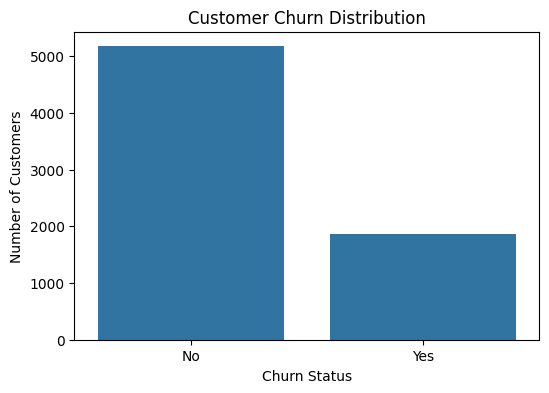

In [45]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

plt.show()

#### 6.5 Churn Percentage

In [46]:
churn_percentage = df['Churn'].value_counts(normalize=True) * 100

print(churn_percentage)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


#### 6.6 Gender Analysis

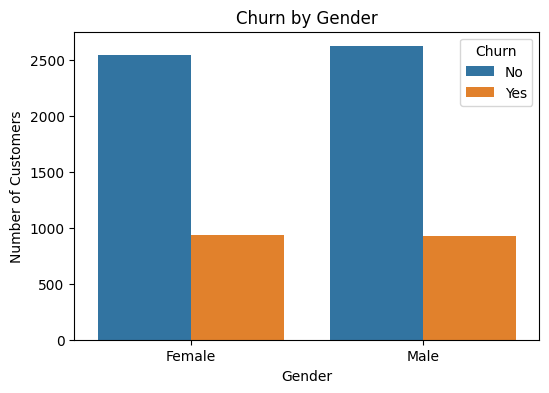

In [47]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='gender', hue='Churn')

plt.title('Churn by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

plt.show()

#### 6.7 Contract Analysis

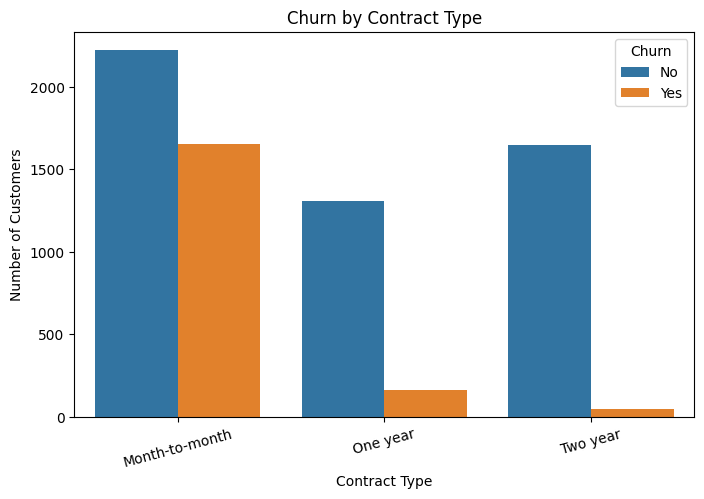

In [48]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Contract', hue='Churn')

plt.title('Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')

plt.xticks(rotation=15)
plt.show()

#### 6.8 Tenure Analysis

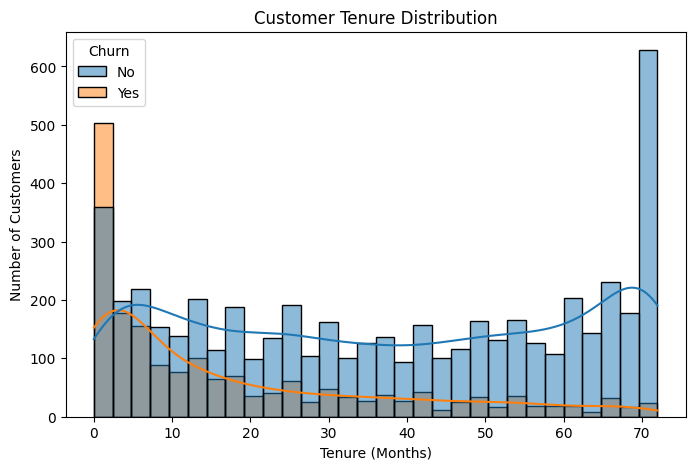

In [49]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='tenure', hue='Churn',
             bins=30, kde=True)

plt.title('Customer Tenure Distribution')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')

plt.show()

#### 6.9 Monthly Charges Analysis

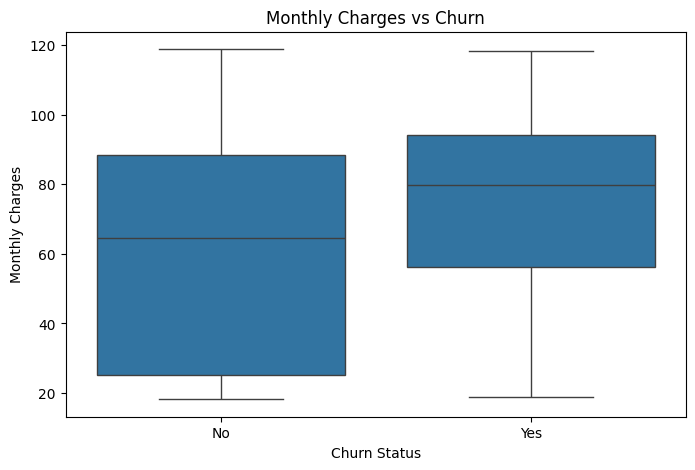

In [50]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Churn', y='MonthlyCharges')

plt.title('Monthly Charges vs Churn')
plt.xlabel('Churn Status')
plt.ylabel('Monthly Charges')

plt.show()

#### 6.10 Total Charges Analysis

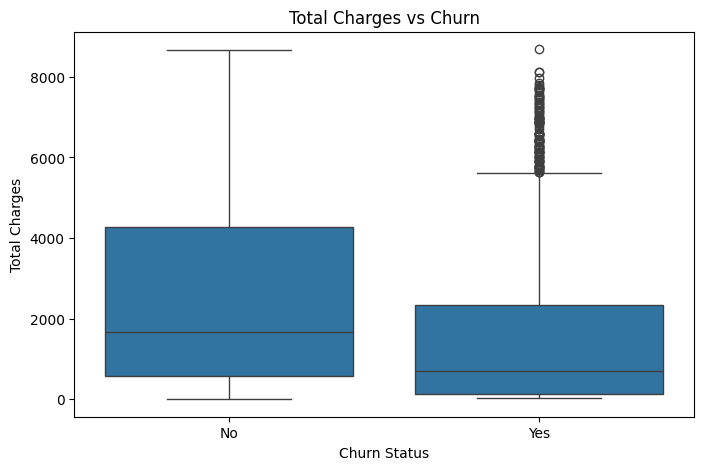

In [51]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Churn', y='TotalCharges')

plt.title('Total Charges vs Churn')
plt.xlabel('Churn Status')
plt.ylabel('Total Charges')

plt.show()

#### 6.11 Correlation Analysis

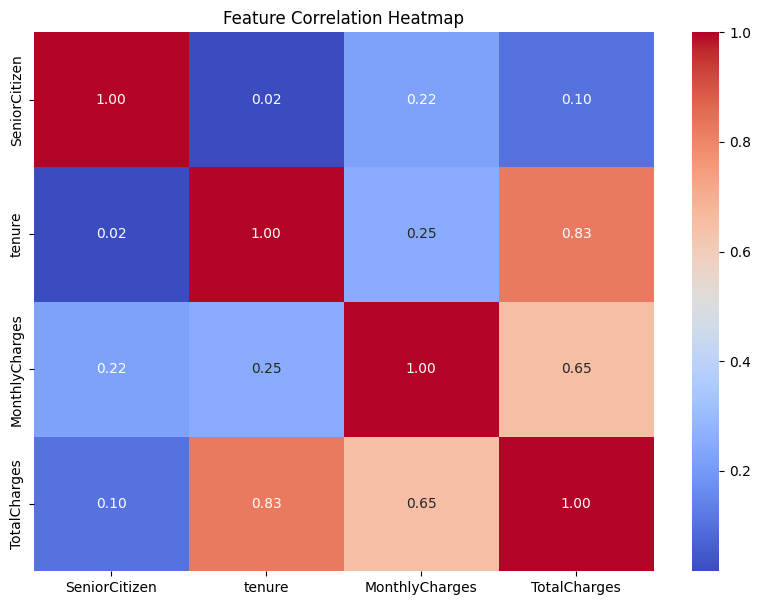

In [52]:
plt.figure(figsize=(10, 7))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Feature Correlation Heatmap')
plt.show()

#### 6.12 Churn Correlation

In [53]:
df_encoded = df.copy()

df_encoded['Churn'] = df_encoded['Churn'].map({
    'No': 0,
    'Yes': 1
})

churn_corr = df_encoded.select_dtypes(include=np.number).corr()

print(churn_corr['Churn'].sort_values(ascending=False))

Churn             1.000000
MonthlyCharges    0.193356
SeniorCitizen     0.150889
TotalCharges     -0.198324
tenure           -0.352229
Name: Churn, dtype: float64


#### 6.13 EDA Summary

In [54]:
print("Total Customers:", len(df))
print("Churned Customers:", (df['Churn'] == 'Yes').sum())
print("Retained Customers:", (df['Churn'] == 'No').sum())

print("\nChurn Rate:",
      round((df['Churn'] == 'Yes').mean() * 100, 2), "%")

Total Customers: 7043
Churned Customers: 1869
Retained Customers: 5174

Churn Rate: 26.54 %


## Step 7: Feature Engineering

#### 7.1 Remove Unnecessary Columns

In [55]:
df = df.drop(columns=['customerID'])

df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


#### 7.2 Separate Features

In [56]:
X = df.drop(columns=['Churn'])

y = df['Churn']

#### 7.3 Encode Target

In [57]:
y = y.map({
    'No': 0,
    'Yes': 1
})

y.head()

0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

#### 7.4 Check Features

In [58]:
print("Feature Shape:", X.shape)

print("\nNumerical Features:")
print(X.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical Features:")
print(X.select_dtypes(include='object').columns.tolist())

Feature Shape: (7043, 19)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


#### 7.5 Split Dataset

In [59]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (5634, 19)
Testing Features: (1409, 19)

Training Target: (5634,)
Testing Target: (1409,)


#### 7.6 Check Distribution

In [60]:
print("Training Data:")
print(y_train.value_counts())

print("\nTesting Data:")
print(y_test.value_counts())

Training Data:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing Data:
Churn
0    1035
1     374
Name: count, dtype: int64


## Step 8: Data Preprocessing

#### 8.1 Identify Features

In [61]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()

categorical_features = X_train.select_dtypes(include='object').columns.tolist()

print("Numerical Features:", numeric_features)
print("\nCategorical Features:", categorical_features)

Numerical Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


#### 8.2 Numerical Pipeline

In [62]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

print("Numerical Pipeline Created Successfully!")

Numerical Pipeline Created Successfully!


#### 8.3 Categorical Pipeline

In [63]:
from sklearn.preprocessing import OneHotEncoder

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

print("Categorical Pipeline Created Successfully!")

Categorical Pipeline Created Successfully!


#### 8.4 Create Column Transformer

In [64]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Column Transformer Created Successfully!")

Column Transformer Created Successfully!


#### 8.5 Transform Training Data

In [65]:
X_train_processed = preprocessor.fit_transform(X_train)

print("Training Data Shape:", X_train_processed.shape)

Training Data Shape: (5634, 45)


#### 8.6 Transform Testing Data

In [66]:
X_test_processed = preprocessor.transform(X_test)

print("Testing Data Shape:", X_test_processed.shape)

Testing Data Shape: (1409, 45)


#### 8.7 Final Verification

In [67]:
print("Training Data:", X_train_processed.shape)
print("Testing Data:", X_test_processed.shape)

print("\nMissing Values in Training:",
      np.isnan(X_train_processed.toarray() if hasattr(X_train_processed, "toarray") else X_train_processed).sum())

print("Missing Values in Testing:",
      np.isnan(X_test_processed.toarray() if hasattr(X_test_processed, "toarray") else X_test_processed).sum())

Training Data: (5634, 45)
Testing Data: (1409, 45)

Missing Values in Training: 0
Missing Values in Testing: 0


## Step 9: Model Training

#### 9.1 Import Models

In [68]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.pipeline import Pipeline
from sklearn.base import clone

print("Models Imported Successfully!")

Models Imported Successfully!


#### 9.2 Define Models

In [69]:
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

print("Total Models:", len(models))

Total Models: 3


#### 9.3 Create Model Pipelines

In [70]:
model_pipelines = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', clone(preprocessor)),
        ('classifier', model)
    ])

    model_pipelines[name] = pipeline

print("Model Pipelines Created Successfully!")

Model Pipelines Created Successfully!


#### 9.4 Train Models

In [71]:
trained_models = {}

for name, pipeline in model_pipelines.items():

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(f"{name} Trained Successfully!")

Logistic Regression Trained Successfully!
Decision Tree Trained Successfully!
Random Forest Trained Successfully!


#### 9.5 Verify Trained Models

In [72]:
for name, model in trained_models.items():

    print(name)
    print("Training Status:", "Completed")
    print("-" * 35)

Logistic Regression
Training Status: Completed
-----------------------------------
Decision Tree
Training Status: Completed
-----------------------------------
Random Forest
Training Status: Completed
-----------------------------------


## Step 10: Model Evaluation

#### 10.1 Import Metrics

In [74]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Evaluation Metrics Imported!")

Evaluation Metrics Imported!


#### 10.2 Evaluate Models

In [75]:
results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='F1 Score',
    ascending=False
).reset_index(drop=True)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8421
1,Random Forest,0.7864,0.6254,0.4866,0.5474,0.8185
2,Decision Tree,0.7211,0.4755,0.4920,0.4836,0.6477


#### 10.3 Confusion Matrix

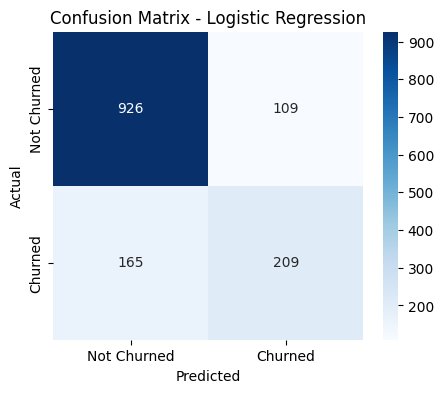

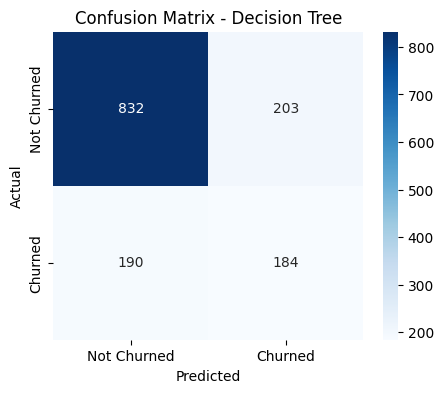

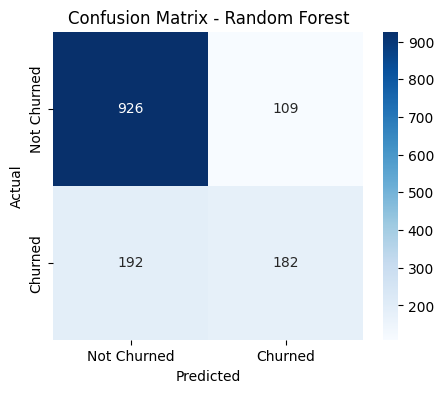

In [76]:
for name, model in trained_models.items():
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Not Churned', 'Churned'],
        yticklabels=['Not Churned', 'Churned']
    )

    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

#### 10.4 Classification Report

In [77]:
for name, model in trained_models.items():
    print(f"\n{name}")
    print("-" * 50)

    y_pred = model.predict(X_test)

    print(classification_report(
        y_test,
        y_pred,
        target_names=['Not Churned', 'Churned']
    ))


Logistic Regression
--------------------------------------------------
              precision    recall  f1-score   support

 Not Churned       0.85      0.89      0.87      1035
     Churned       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


Decision Tree
--------------------------------------------------
              precision    recall  f1-score   support

 Not Churned       0.81      0.80      0.81      1035
     Churned       0.48      0.49      0.48       374

    accuracy                           0.72      1409
   macro avg       0.64      0.65      0.65      1409
weighted avg       0.72      0.72      0.72      1409


Random Forest
--------------------------------------------------
              precision    recall  f1-score   support

 Not Churned       0.83      0.89      0.86      1035
     Churned       0.63      0.49

#### 10.5 Best Model

In [78]:
best_model_name = results_df.iloc[0]['Model']

print("Best Model:", best_model_name)
print("Best F1 Score:", round(results_df.iloc[0]['F1 Score'], 4))
print("Best ROC-AUC:", round(results_df.iloc[0]['ROC-AUC'], 4))

Best Model: Logistic Regression
Best F1 Score: 0.604
Best ROC-AUC: 0.8421


## Step 11: Cross Validation

#### 11.1 Import Libraries

In [79]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

print("Cross Validation Imported!")

Cross Validation Imported!


#### 11.2 Define Cross Validation

In [80]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross Validation Folds:", cv.get_n_splits())

Cross Validation Folds: 5


#### 11.3 Evaluate Models

In [81]:
cv_results = []

for name, model in model_pipelines.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring='f1',
        n_jobs=-1
    )

    cv_results.append({
        'Model': name,
        'Mean F1 Score': scores.mean(),
        'Std F1 Score': scores.std()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df.sort_values(
    by='Mean F1 Score',
    ascending=False
).round(4)

,Model,Mean F1 Score,Std F1 Score
0,Logistic Regression,0.5923,0.0299
2,Random Forest,0.5394,0.0290
1,Decision Tree,0.4909,0.0151


#### 11.4 Compare Results

In [82]:
print("Test Set Results:")
display(results_df[['Model', 'F1 Score', 'ROC-AUC']])

print("Cross Validation Results:")
display(cv_results_df.sort_values(
    by='Mean F1 Score',
    ascending=False
))

Test Set Results:


,Model,F1 Score,ROC-AUC
0,Logistic Regression,0.604046,0.842135
1,Random Forest,0.547368,0.818510
2,Decision Tree,0.483574,0.647676


Cross Validation Results:


,Model,Mean F1 Score,Std F1 Score
0,Logistic Regression,0.592329,0.029851
2,Random Forest,0.539393,0.028973
1,Decision Tree,0.490920,0.015060


## Step 12: Hyperparameter Tuning

#### 12.1 Import Libraries

In [83]:
from sklearn.model_selection import GridSearchCV

print("GridSearchCV Imported Successfully!")

GridSearchCV Imported Successfully!


#### 12.2 Logistic Regression

In [84]:
lr_pipeline = model_pipelines['Logistic Regression']

lr_params = {
    'classifier__C': [0.01, 0.1, 1, 10],
    'classifier__solver': ['liblinear', 'lbfgs'],
    'classifier__class_weight': [None, 'balanced']
}

lr_grid = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_params,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

lr_grid.fit(X_train, y_train)

Fitting 5 folds for each of 16 candidates, totalling 80 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.01, 0.1, ...], 'classifier__class_weight': [None, 'balanced'], 'classifier__solver': ['liblinear', 'lbfgs']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevalua

#### 12.3 Best Parameters

In [85]:
print("Best Parameters:", lr_grid.best_params_)
print("Best CV F1 Score:", round(lr_grid.best_score_, 4))

Best Parameters: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'classifier__solver': 'liblinear'}
Best CV F1 Score: 0.6295


#### 12.4 Random Forest

In [86]:
rf_pipeline = model_pipelines['Random Forest']

rf_params = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_split': [2, 5],
    'classifier__min_samples_leaf': [1, 2],
    'classifier__class_weight': [None, 'balanced']
}

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_params,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

Fitting 5 folds for each of 48 candidates, totalling 240 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__class_weight': [None, 'balanced'], 'classifier__max_depth': [None, 10, ...], 'classifier__min_samples_leaf': [1, 2], 'classifier__min_samples_split': [2, 5], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` par

#### 12.5 Best Parameters

In [87]:
print("Best Parameters:", rf_grid.best_params_)
print("Best CV F1 Score:", round(rf_grid.best_score_, 4))

Best Parameters: {'classifier__class_weight': 'balanced', 'classifier__max_depth': None, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}
Best CV F1 Score: 0.6331


#### 12.6 Compare Tuned Models

In [88]:
tuned_results = pd.DataFrame([
    {
        'Model': 'Logistic Regression',
        'Best CV F1': lr_grid.best_score_
    },
    {
        'Model': 'Random Forest',
        'Best CV F1': rf_grid.best_score_
    }
])

tuned_results.sort_values(
    by='Best CV F1',
    ascending=False
).reset_index(drop=True).round(4)

,Model,Best CV F1
0,Random Forest,0.6331
1,Logistic Regression,0.6295


#### 12.7 Save Best Models

In [89]:
best_models = {
    'Logistic Regression': lr_grid.best_estimator_,
    'Random Forest': rf_grid.best_estimator_
}

print("Tuned Models Saved Successfully!")

Tuned Models Saved Successfully!


## Step 13: Final Model Evaluation

#### 13.1 Evaluate Tuned Models

In [90]:
final_results = []
final_predictions = {}

for name, model in best_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    final_predictions[name] = y_pred

    final_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

final_results_df = pd.DataFrame(final_results)

final_results_df.sort_values(
    by='F1 Score',
    ascending=False
).reset_index(drop=True).round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7410,0.5078,0.7861,0.6170,0.8410
1,Random Forest,0.7544,0.5280,0.7059,0.6041,0.8307


#### 13.2 Compare Before And After

In [91]:
print("Before Tuning:")
display(results_df[['Model', 'F1 Score', 'ROC-AUC']])

print("After Tuning:")
display(final_results_df[['Model', 'F1 Score', 'ROC-AUC']])

Before Tuning:


,Model,F1 Score,ROC-AUC
0,Logistic Regression,0.604046,0.842135
1,Random Forest,0.547368,0.818510
2,Decision Tree,0.483574,0.647676


After Tuning:


,Model,F1 Score,ROC-AUC
0,Logistic Regression,0.616999,0.840983
1,Random Forest,0.604119,0.830723


#### 13.3 Final Confusion Matrix

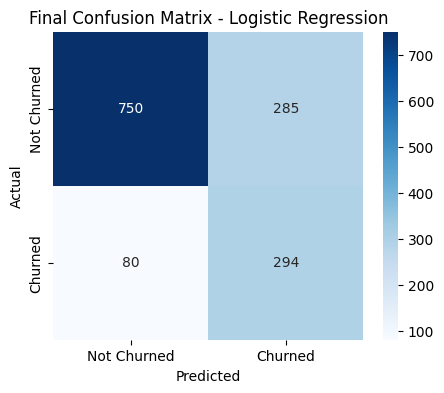

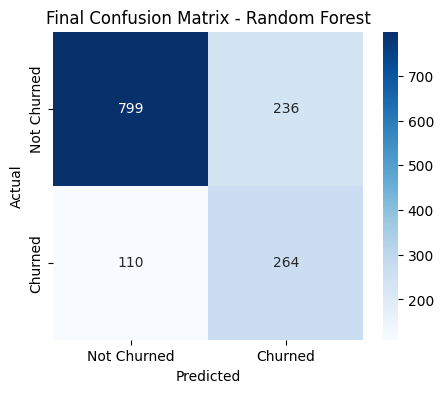

In [92]:
for name, y_pred in final_predictions.items():

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Not Churned', 'Churned'],
        yticklabels=['Not Churned', 'Churned']
    )

    plt.title(f'Final Confusion Matrix - {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

#### 13.4 Select Final Model

In [93]:
best_model_name = final_results_df.sort_values(
    by='F1 Score',
    ascending=False
).iloc[0]['Model']

final_model = best_models[best_model_name]

print("Selected Model:", best_model_name)
print("Final F1 Score:", round(
    final_results_df.set_index('Model').loc[best_model_name, 'F1 Score'], 4
))

Selected Model: Logistic Regression
Final F1 Score: 0.617


## Step 14: Feature Importance

#### 14.1 Extract Features

In [94]:
feature_names = final_model.named_steps['preprocessor'].get_feature_names_out()

print("Total Processed Features:", len(feature_names))

Total Processed Features: 45


#### 14.2 Extract Importance

In [95]:
classifier = final_model.named_steps['classifier']

if hasattr(classifier, 'feature_importances_'):
    importance = classifier.feature_importances_

elif hasattr(classifier, 'coef_'):
    importance = np.abs(classifier.coef_[0])

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

feature_importance_df = feature_importance_df.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

feature_importance_df.head(15)

,Feature,Importance
0,num__tenure,0.980335
1,cat__Contract_Two year,0.692290
2,cat__Contract_Month-to-month,0.629538
3,cat__InternetService_DSL,0.357999
4,cat__InternetService_Fiber optic,0.331094
5,num__TotalCharges,0.293099
6,cat__PaymentMethod_Electronic check,0.247579
7,cat__PaperlessBilling_No,0.241449
8,cat__OnlineSecurity_Yes,0.231143
9,cat__MultipleLines_No,0.215146


#### 14.3 Visualize Importance

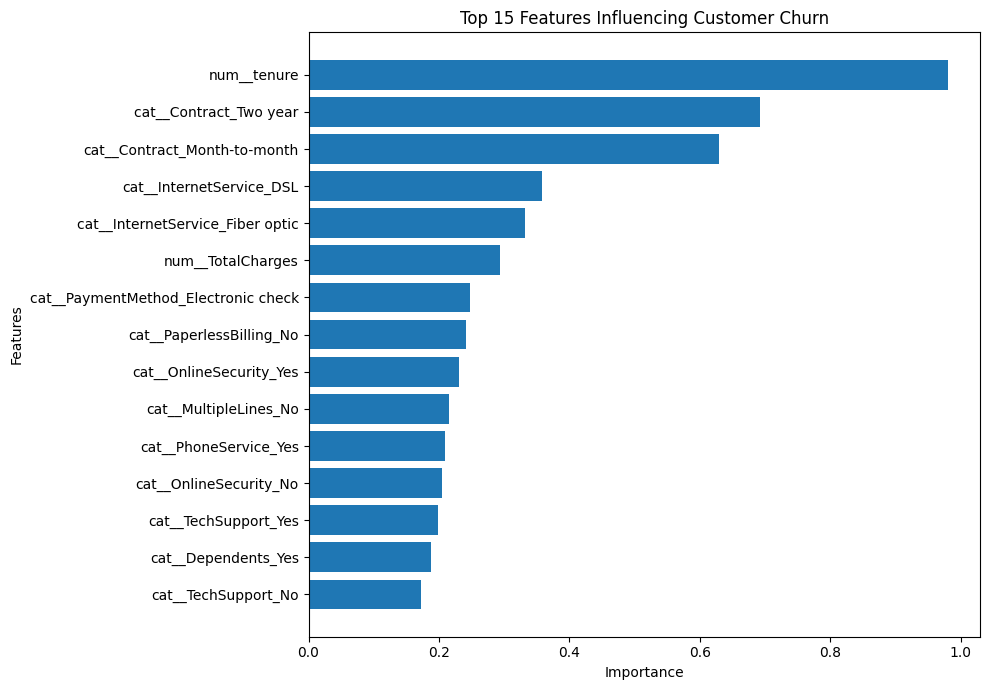

In [96]:
top_features = feature_importance_df.head(15).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.title('Top 15 Features Influencing Customer Churn')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

## Step 15: Save Final Model

#### 15.1 Import Libraries

In [97]:
import os
import pickle

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


#### 15.2 Create Models Folder

In [98]:
os.makedirs("../models", exist_ok=True)

print("Models Folder Created!")

Models Folder Created!


#### 15.3 Save Model

In [99]:
model_path = "../models/customer_churn_model.pkl"

with open(model_path, "wb") as file:
    pickle.dump(final_model, file)

print("Model Saved Successfully!")
print("Model Path:", model_path)

Model Saved Successfully!
Model Path: ../models/customer_churn_model.pkl


#### 15.4 Load Model

In [100]:
with open(model_path, "rb") as file:
    loaded_model = pickle.load(file)

print("Model Loaded Successfully!")

Model Loaded Successfully!


#### 15.5 Test Saved Model

In [101]:
sample_prediction = loaded_model.predict(X_test.iloc[:5])

print("Actual Values:    ", y_test.iloc[:5].values)
print("Predicted Values: ", sample_prediction)

Actual Values:     [0 0 0 0 0]
Predicted Values:  [0 1 0 1 0]


## Step 16: Streamlit Web App

#### 16.1 Install Streamlit

In [102]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


#### 16.2 Create App File

##### Customer-Churn-Prediction/
- │
- ├── Dataset/
- ├── notebooks/
- ├── models/
- │   └── customer_churn_model.pkl
- │
- ├── app.py
- ├── requirements.txt
- └── README.md